# Chapter 99: Structuralist, Feminist, and Ecological Alternatives

This notebook reruns four worked examples from the chapter: growth capped by the balance of payments, the care hours behind extra paid work, durability against material throughput, and import capacity when the terms of trade fall. Every number is one of the chapter's hypothetical values, not data; a few extra input values are added.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def bop_constrained_growth(g_world, ex, em, g_target=None, base=100.0):
    """Thirlwall rule: export growth ex g_world, constrained growth ex g_world / em (percent).

    center-periphery-structuralism (chapter 99): g_world 3, ex 0.7, em 1.5 give export growth 2.1,
    exports 102.1, constrained growth 1.4; at target 5, imports grow 7.5 to 107.5, gap 5.4.
    ex 1.2, em 0.8 give exports 103.6, imports 104, gap 0.4. Implemented by Part 10 (chapter 99).
    """
    gx = ex * g_world
    out = {"export_growth": gx, "exports": base * (1 + gx / 100.0), "g_bp": gx / em}
    if g_target is not None:
        gm = em * g_target
        out.update({"import_growth": gm, "imports": base * (1 + gm / 100.0)})
        out["gap"] = out["imports"] - out["exports"]
    return out


def import_capacity(PC, PM, Q):
    """Terms of trade T = PC / PM and import capacity T Q.

    prebisch-singer-hypothesis (chapter 99): T = 0.8; 0.8 x 10,000 = 8,000; 0.8 x 11,500 = 9,200,
    2,300 below the T = 1 path of 11,500. Implemented by Part 10 (chapter 99).
    """
    T = PC / PM
    return {"T": T, "capacity": T * Q, "at_T1": Q, "loss_vs_T1": Q - T * Q}


def time_budget(T, paid, care):
    """Rest from the weekly time identity h + c + r = T: returns r = T - h - c.

    social-reproduction-and-unpaid-care (chapter 99): T = 112; Ana 25 paid, 35 care gives rest 52;
    Ben 40 paid, 15 care gives 57; Ana 40 paid, 35 care gives 37.
    """
    return T - paid - care


def stock_flow_throughput(K, d, extra=0.0, intensity=100.0, ceiling=None):
    """Stock maintenance: replacements d K, builds d K + extra, Delta K = I - d K, throughput builds x intensity.

    steady-state-economy (chapter 99): K = 4,000, d = 0.02 give 80 replacements and 8,000 tonnes,
    3,000 over a 5,000 ceiling; d = 0.01 gives 4,000 tonnes and 1,000 headroom; 20 extra dwellings
    give 6,000 tonnes and Delta K = 20. Implemented by Part 10 (chapter 99 is its first user).
    """
    repl = d * K
    builds = repl + extra
    out = {"replacements": repl, "builds": builds, "dK": builds - repl, "throughput": builds * intensity}
    if ceiling is not None:
        out["over"] = out["throughput"] - ceiling
    return out


plt.rcParams.update(HOUSE_RC)


trade = SimpleNamespace(bop_constrained_growth=bop_constrained_growth, import_capacity=import_capacity)


labor = SimpleNamespace(time_budget=time_budget)


growth = SimpleNamespace(stock_flow_throughput=stock_flow_throughput)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'center-periphery-structuralism': {'base': 100,
                                    'g_world': 3,
                                    'ex': 0.7,
                                    'em': 1.5,
                                    'exports': 102.1,
                                    'g_target': 5,
                                    'imports': 107.5,
                                    'gap': 5.4,
                                    'g_bp': 1.4,
                                    'ex_new': 1.2,
                                    'em_new': 0.8,
                                    'exports_new': 103.6,
                                    'imports_new': 104,
                                    'gap_new': 0.4},
 'social-reproduction-and-unpaid-care': {'T': 112,
                                         'need': 50,
                                         'ana': {'care': 35, 'paid': 25, 'wage': 20, 'rest': 52},
                                         'ben': {'care': 15, 'paid': 40, 'wage': 25, 'rest': 57},
                                         'earnings': 1500,
                                         'extra': 15,
                                         'gain': 300,
                                         'service': 15,
                                         'fee': 60,
                                         'net': 240,
                                         'ben_rest_alt': 42,
                                         'ana_rest_alt': 37},
 'steady-state-economy': {'K': 4000,
                          'd': 0.02,
                          'repl': 80,
                          'intensity': 100,
                          'throughput': 8000,
                          'd_low': 0.01,
                          'repl_low': 40,
                          'throughput_low': 4000,
                          'ceiling': 5000,
                          'headroom': 1000,
                          'over': 3000,
                          'extra': 20,
                          'throughput_rebound': 6000},
 'prebisch-singer-hypothesis': {'PC': 80,
                                'PM': 100,
                                'Q': 10000,
                                'T': 0.8,
                                'cap': 8000,
                                'Q_new': 11500,
                                'cap_new': 9200,
                                'loss_vs_T1': 2300},
 'constructed': {'center-periphery-structuralism': {'g_target': [3]},
                 'social-reproduction-and-unpaid-care': {'fee': [120]},
                 'steady-state-economy': {'d': [0.015]},
                 'prebisch-singer-hypothesis': {'PC': [70]}}}


LABEL = "Hypothetical teaching numbers, not data."


def bop_picture(ex=0.7, em=1.5, g=5):
    b = BV["center-periphery-structuralism"]
    r = trade.bop_constrained_growth(b["g_world"], ex, em, g, b["base"])
    X, M, gap = r["exports"], r["imports"], r["gap"]
    fig, ax = new_figure()
    bar_compare(ax, ["Exports after a year", "Imports after a year"], [X, M], colors=["teal", "terracotta"],
                value_labels=[num(X, 1), num(M, 1)], ylabel="Billions (hypothetical)", xlabel="Flow")
    hline(ax, 100, "starting flows 100", col="grey")
    ax.set_ylim(90, 112)
    if gap > 1e-9:
        bal = f"a deficit of {num(gap, 1)} billion"
    elif gap < -1e-9:
        bal = f"a surplus of {num(-gap, 1)} billion"
    else:
        bal = "balanced trade"
    gbp = round(r["g_bp"], 9)
    gbp2 = num(int(gbp * 100 + 0.5) / 100, 2)  # half up: 2.1 / 0.8 = 2.625 shows as 2.63
    metrics = {"Exports": num(X, 1), "Imports": num(M, 1), "Gap (imports minus exports)": num(gap, 1),
               "Growth consistent with balance": pct(round(r["g_bp"], 9) / 100, 1)}
    steps = [f"Export growth = {num(ex, 1)} x 3 = {num(r['export_growth'], 1)}%, so exports = {num(X, 1)}",
             f"Import growth = {num(em, 1)} x {g} = {num(r['import_growth'], 1)}%, so imports = {num(M, 1)}",
             f"Gap = {num(M, 1)} - {num(X, 1)} = {num(gap, 1)}",
             f"Balance-constrained growth = {num(r['export_growth'], 1)} / {num(em, 1)} = {gbp2}%"]
    if gbp < g:
        cap = f"Without financing, growth is held to {num(r['export_growth'], 1)} / {num(em, 1)} = {gbp2} percent."
    else:
        cap = (f"Growth of up to {num(r['export_growth'], 1)} / {num(em, 1)} = {gbp2} percent is consistent with "
               f"balance, so the {g} percent target needs no financing.")
    interp = (f"{LABEL} With center growth of 3 percent, exports grow {num(ex, 1)} x 3 = {num(r['export_growth'], 1)} "
              f"percent to {num(X, 1)}. Growing {g} percent raises imports {num(em, 1)} x {g} = "
              f"{num(r['import_growth'], 1)} percent to {num(M, 1)}, leaving {bal}. {cap}")
    alt = (f"Two bars against a line at 100: exports {num(X, 1)} and imports {num(M, 1)} after a year of {g} percent "
           f"growth.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def care_picture(extra=15, serv=15, fee=60):
    b = BV["social-reproduction-and-unpaid-care"]
    T, ana, ben = b["T"], b["ana"], b["ben"]
    a_paid = ana["paid"] + extra
    a_care = ana["care"] - serv
    a_rest = labor.time_budget(T, a_paid, a_care)
    b_rest = labor.time_budget(T, ben["paid"], ben["care"])
    charge = fee if serv > 0 else 0
    earn = a_paid * ana["wage"] + ben["paid"] * ben["wage"]
    net = earn - b["earnings"] - charge
    fig, ax = new_figure()
    names = ["Ana", "Ben"]
    xs = np.arange(2)
    paid, care, rest = [a_paid, ben["paid"]], [a_care, ben["care"]], [a_rest, b_rest]
    ax.bar(xs, paid, width=0.55, color=PALETTE["navy"], label="paid work")
    ax.bar(xs, care, bottom=paid, width=0.55, color=PALETTE["gold"], label="unpaid care")
    ax.bar(xs, rest, bottom=np.add(paid, care), width=0.55, color=PALETTE["grey"], alpha=0.5, label="rest")
    for x in xs:
        for lo, h, t in ((0, paid[x], "paid"), (paid[x], care[x], "care"), (paid[x] + care[x], rest[x], "rest")):
            label(ax, x, lo + h / 2, f"{t} {num(h, 0)}", dx=0, dy=0, ha="center", va="center")
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, 2.2)
    ax.set_ylim(0, 125)
    ax.set_ylabel("Hours per week")
    ax.set_xlabel("Adult")
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    if serv > 0:
        cover = (f"Ana's {num(a_care, 0)} and Ben's {ben['care']} own care hours plus {serv} purchased hours meet the "
                 f"50 hour need")
    else:
        cover = f"Ana's {num(a_care, 0)} and Ben's {ben['care']} own care hours meet the 50 hour need"
    fee_text = f"the service charge of {money(fee, 0)}" if serv > 0 else "no service charge (no care is purchased)"
    metrics = {"Weekly earnings": money(earn, 0), "Net cash change": money(net, 0), "Ana's rest (hours)": num(a_rest, 0),
               "Ben's rest (hours)": num(b_rest, 0)}
    steps = [f"Ana: rest = 112 - {a_paid} - {num(a_care, 0)} = {num(a_rest, 0)}",
             f"Earnings = {a_paid} x 20 + 40 x 25 = {num(a_paid * 20, 0)} + 1,000 = {num(earn, 0)}",
             f"Net cash change = {num(earn, 0)} - 1,500 - {charge} = {num(net, 0)}"]
    interp = (f"{LABEL} Ana works {a_paid} paid hours and gives {num(a_care, 0)} care hours, so her rest is 112 - "
              f"{a_paid} - {num(a_care, 0)} = {num(a_rest, 0)} hours. {cover}. Earnings are {money(earn, 0)}; after "
              f"{fee_text}, household cash changes by {money(net, 0)} a week.")
    if extra > 0 and serv == 0:
        interp += (" Without replacement care the extra paid hours come out of Ana's rest here; if Ben covered them "
                   "instead, his rest would fall to 42.")
    alt = (f"Two stacked 112 hour bars. Ana: paid {a_paid}, care {num(a_care, 0)}, rest {num(a_rest, 0)}. Ben: paid 40, "
           f"care 15, rest 57. Net cash change {money(net, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def throughput_picture(d=0.02, extra=0):
    b = BV["steady-state-economy"]
    r = growth.stock_flow_throughput(b["K"], d, extra, b["intensity"], b["ceiling"])
    tp, over = r["throughput"], r["over"]
    fig, ax = new_figure()
    parts = [r["replacements"] * b["intensity"], extra * b["intensity"], tp]
    bar_compare(ax, ["Replacement", "Extra dwellings", "Total throughput"], parts,
                colors=["teal", "terracotta", "gold"], value_labels=[num(v, 0) for v in parts],
                ylabel="Tonnes of material per year", xlabel="Use of material")
    hline(ax, b["ceiling"], "ceiling 5,000 tonnes", col="navy")
    ax.set_ylim(0, 11500)
    if over > 0:
        verdict = f"{num(over, 0)} tonnes over the ceiling"
    elif over < 0:
        verdict = f"{num(-over, 0)} tonnes of headroom under the ceiling"
    else:
        verdict = "exactly at the ceiling"
    metrics = {"Replacements": num(r["replacements"], 0), "Throughput (tonnes)": num(tp, 0),
               "Against ceiling": verdict, "Stock change Delta K": num(r["dK"], 0)}
    steps = [f"Replacements = {num(d, 3)} x 4,000 = {num(r['replacements'], 0)}",
             f"Throughput = ({num(r['replacements'], 0)} + {extra}) x 100 = {num(tp, 0)} tonnes",
             f"Delta K = {num(r['builds'], 0)} - {num(r['replacements'], 0)} = {num(r['dK'], 0)}"]
    ext = f"{extra} extra dwellings" if extra else "no extra dwellings"
    interp = (f"{LABEL} At {pct(d, 1)} depreciation the town replaces {num(d, 3)} x 4,000 = {num(r['replacements'], 0)} "
              f"dwellings a year; with {ext} throughput is {num(tp, 0)} tonnes, {verdict}. Durability "
              f"cuts throughput only if the stock is held fixed; extra building is growth, not a steady state.")
    alt = (f"Bars of material used for replacement ({num(parts[0], 0)} tonnes) and extra building ({num(parts[1], 0)} "
           f"tonnes) and a total bar of {num(tp, 0)} tonnes, against a ceiling line at 5,000.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tot_picture(pc=80, q=11500):
    b = BV["prebisch-singer-hypothesis"]
    r = trade.import_capacity(pc, b["PM"], q)
    cap = r["capacity"]
    base = b["Q"]
    fig, ax = new_figure()
    vals = [base, q, cap]
    bar_compare(ax, ["Original (T = 1, 10,000)", "T = 1 path", "Actual"], vals, colors=["grey", "teal", "terracotta"],
                value_labels=[num(v, 0) for v in vals], ylabel="Machinery units purchasable", xlabel="Case")
    ax.set_ylim(0, 14000)
    diff = cap - base
    vs_base = (f"{num(-diff, 0)} fewer than" if diff < 0 else (f"{num(diff, 0)} more than" if diff > 0 else "equal to"))
    metrics = {"Terms of trade T": num(r["T"], 2), "Import capacity": num(cap, 0),
               "Against original 10,000": vs_base.replace(" than", "").replace(" to", ""),
               "Loss against T = 1 path": num(r["loss_vs_T1"], 0)}
    steps = [f"T = {pc} / 100 = {num(r['T'], 2)}",
             f"Import capacity = {num(r['T'], 2)} x {q:,} = {num(cap, 0)}",
             f"Against the T = 1 path: {q:,} - {num(cap, 0)} = {num(r['loss_vs_T1'], 0)}"]
    interp = (f"{LABEL} With the cocoa index at {pc} the terms of trade are {num(r['T'], 2)}, so {q:,} units of cocoa "
              f"buy {num(r['T'], 2)} x {q:,} = {num(cap, 0)} machinery units, {vs_base} the original 10,000 and "
              + (f"{num(r['loss_vs_T1'], 0)} below what the same exports would buy at T = 1." if r["loss_vs_T1"] > 1e-9
                 else "exactly what the same exports buy at T = 1."))
    alt = (f"Three bars: original 10,000, T = 1 path {num(q, 0)} and actual import capacity {num(cap, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Center-periphery structuralism: balance-of-payments-constrained growth

Hypothetical: exports and imports start at 100 billion and the center grows 3 percent, with $\eta_x=0.7$ and $\eta_m=1.5$. Constrained growth is $2.1/1.5=1.4\%$.

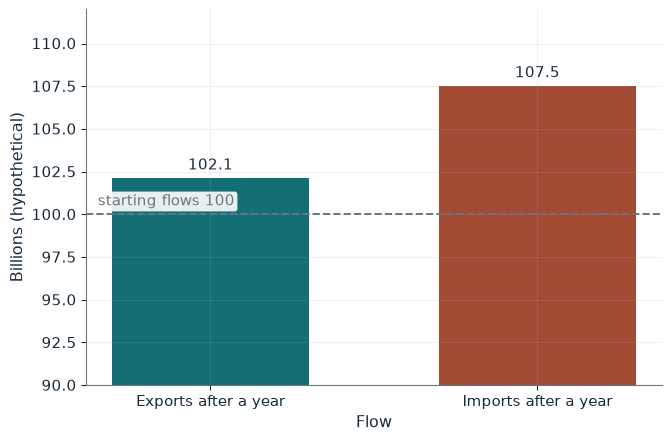

Exports                         102.1
Imports                         107.5
Gap (imports minus exports)     5.4
Growth consistent with balance  1.4%

Worked steps:
  1. Export growth = 0.7 x 3 = 2.1%, so exports = 102.1
  2. Import growth = 1.5 x 5 = 7.5%, so imports = 107.5
  3. Gap = 107.5 - 102.1 = 5.4
  4. Balance-constrained growth = 2.1 / 1.5 = 1.40%

Hypothetical teaching numbers, not data. With center growth of 3 percent, exports grow 0.7 x 3 = 2.1 percent to 102.1. Growing 5 percent raises imports 1.5 x 5 = 7.5 percent to 107.5, leaving a deficit of 5.4 billion. Without financing, growth is held to 2.1 / 1.5 = 1.40 percent.


In [2]:
show(bop_picture(ex=0.7, em=1.5, g=5))

Change one input, `ex`, and hold the others at the book's values:

In [3]:
sweep(bop_picture, 'ex', [0.7, 1.2], {'em': 0.8, 'g': 5}, ['Exports', 'Imports', 'Gap (imports minus exports)'])

ex | Exports | Imports | Gap (imports minus exports)
0.7 | 102.1 | 104.0 | 1.9
1.2 | 103.6 | 104.0 | 0.4


Growing 5 percent raises imports 7.5 percent, from 100 to 107.5, against exports of 102.1: a gap of 5.4. After structural change (1.2 and 0.8) the gap is 0.4.

## 2. Social reproduction and unpaid care: paid hours need replacement care

Hypothetical household: 112 waking hours each, a 50 hour care need, Ana 25 paid and 35 care hours at \$20, Ben 40 paid and 15 care hours at \$25.

$$h_i+c_i+r_i=T_i$$

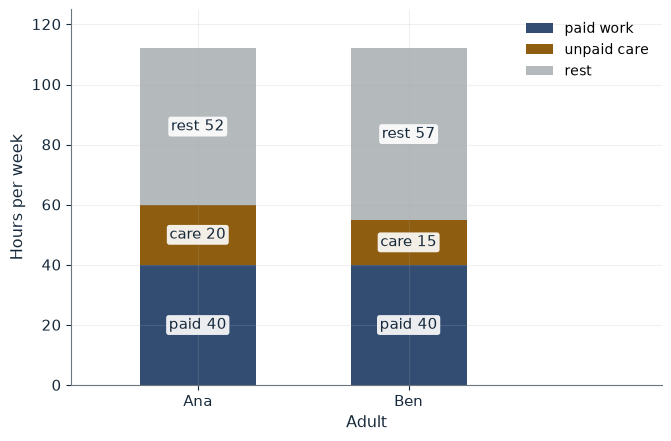

Weekly earnings     $1,800
Net cash change     $240
Ana's rest (hours)  52
Ben's rest (hours)  57

Worked steps:
  1. Ana: rest = 112 - 40 - 20 = 52
  2. Earnings = 40 x 20 + 40 x 25 = 800 + 1,000 = 1,800
  3. Net cash change = 1,800 - 1,500 - 60 = 240

Hypothetical teaching numbers, not data. Ana works 40 paid hours and gives 20 care hours, so her rest is 112 - 40 - 20 = 52 hours. Ana's 20 and Ben's 15 own care hours plus 15 purchased hours meet the 50 hour need. Earnings are $1,800; after the service charge of $60, household cash changes by $240 a week.


In [4]:
show(care_picture(extra=15, serv=15, fee=60))

Change one input, `serv`, and hold the others at the book's values:

In [5]:
sweep(care_picture, 'serv', [0, 15], {'extra': 15, 'fee': 60}, ['Net cash change', "Ana's rest (hours)"])

serv | Net cash change | Ana's rest (hours)
0 | $300 | 37
15 | $240 | 52


Without replacement care, Ana's 15 extra hours cut her rest from 52 to 37 (or Ben's to 42). With 15 purchased hours for \$60, Ana's 20 and Ben's 15 own care hours plus the service meet the need, her rest stays 52 and cash rises by \$240.

## 3. Steady-state economy: durability versus throughput

Hypothetical town: 4,000 dwellings, 100 tonnes per dwelling built, ceiling 5,000 tonnes.

$$\Delta K_p=I_p-dK_p$$

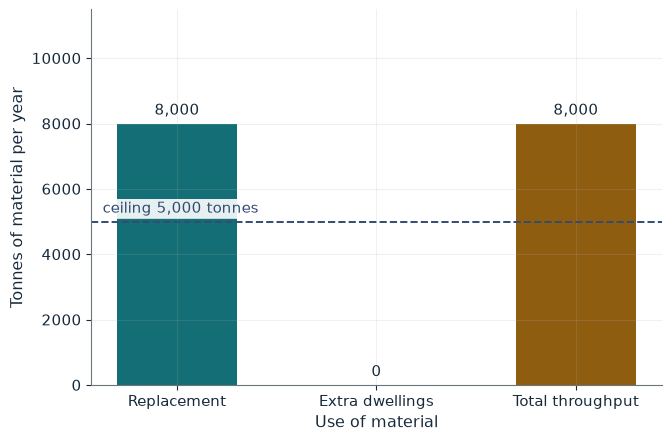

Replacements          80
Throughput (tonnes)   8,000
Against ceiling       3,000 tonnes over the ceiling
Stock change Delta K  0

Worked steps:
  1. Replacements = 0.020 x 4,000 = 80
  2. Throughput = (80 + 0) x 100 = 8,000 tonnes
  3. Delta K = 80 - 80 = 0

Hypothetical teaching numbers, not data. At 2.0% depreciation the town replaces 0.020 x 4,000 = 80 dwellings a year; with no extra dwellings throughput is 8,000 tonnes, 3,000 tonnes over the ceiling. Durability cuts throughput only if the stock is held fixed; extra building is growth, not a steady state.


In [6]:
show(throughput_picture(d=0.02, extra=0))

Change one input, `d`, and hold the others at the book's values:

In [7]:
sweep(throughput_picture, 'd', [0.01, 0.015, 0.02], {'extra': 0}, ['Throughput (tonnes)', 'Against ceiling'])

d | Throughput (tonnes) | Against ceiling
0.01 | 4,000 | 1,000 tonnes of headroom under the ceiling
0.015 | 6,000 | 1,000 tonnes over the ceiling
0.02 | 8,000 | 3,000 tonnes over the ceiling


At 2 percent depreciation throughput is 8,000 tonnes, 3,000 over; at 1 percent it is 4,000. Twenty rebound dwellings push it back to 6,000.

## 4. Prebisch-Singer hypothesis: terms of trade and import capacity

Hypothetical cocoa exporter: machinery index 100; cocoa index 100, then 80.

$$0.8\times10{,}000=8{,}000, \qquad 0.8\times11{,}500=9{,}200$$

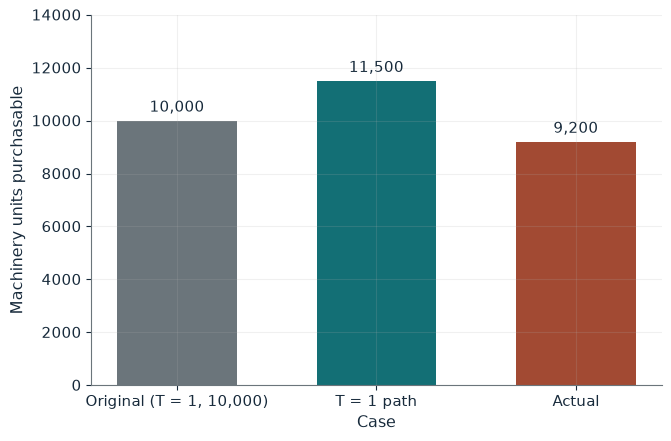

Terms of trade T         0.80
Import capacity          9,200
Against original 10,000  800 fewer
Loss against T = 1 path  2,300

Worked steps:
  1. T = 80 / 100 = 0.80
  2. Import capacity = 0.80 x 11,500 = 9,200
  3. Against the T = 1 path: 11,500 - 9,200 = 2,300

Hypothetical teaching numbers, not data. With the cocoa index at 80 the terms of trade are 0.80, so 11,500 units of cocoa buy 0.80 x 11,500 = 9,200 machinery units, 800 fewer than the original 10,000 and 2,300 below what the same exports would buy at T = 1.


In [8]:
show(tot_picture(pc=80, q=11500))

Change one input, `pc`, and hold the others at the book's values:

In [9]:
sweep(tot_picture, 'pc', [70, 80, 100], {'q': 11500}, ['Import capacity', 'Loss against T = 1 path'])

pc | Import capacity | Loss against T = 1 path
70 | 8,050 | 3,450
80 | 9,200 | 2,300
100 | 11,500 | 0


Raising exports by 15 percent to 11,500 buys 9,200 machinery units, 800 fewer than the original 10,000 and 2,300 fewer than at T = 1.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

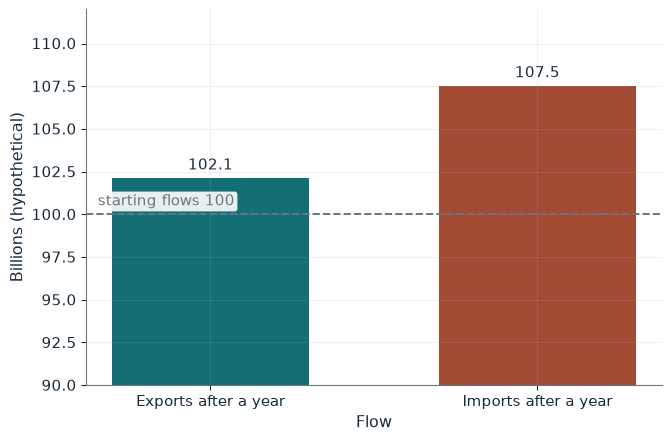

Exports                         102.1
Imports                         107.5
Gap (imports minus exports)     5.4
Growth consistent with balance  1.4%

Worked steps:
  1. Export growth = 0.7 x 3 = 2.1%, so exports = 102.1
  2. Import growth = 1.5 x 5 = 7.5%, so imports = 107.5
  3. Gap = 107.5 - 102.1 = 5.4
  4. Balance-constrained growth = 2.1 / 1.5 = 1.40%

Hypothetical teaching numbers, not data. With center growth of 3 percent, exports grow 0.7 x 3 = 2.1 percent to 102.1. Growing 5 percent raises imports 1.5 x 5 = 7.5 percent to 107.5, leaving a deficit of 5.4 billion. Without financing, growth is held to 2.1 / 1.5 = 1.40 percent.


In [10]:
show(bop_picture(ex=0.7, em=1.5, g=5))

## Practice

**1.** With eta_x 1.2, eta_m 1.5 and a 3 percent target, what are the gap and constrained growth?

<details><summary>Answer</summary>

Exports 103.6, imports 104.5, gap 0.9; growth 3.6 / 1.5 = 2.4 percent.

</details>

**2.** With the service at a \$120 charge and Ana's 15 extra hours, what is the net cash gain?

<details><summary>Answer</summary>

15 x 20 - 120 = \$180.

</details>

**3.** With P_C = 70 and 11,500 units exported, what is import capacity?

<details><summary>Answer</summary>

0.7 x 11,500 = 8,050, 1,950 below 10,000.

</details>